# Classifying Engine Faults

This notebook contains the code for the report *Evaluating Variable Subsets and Classifers for Engine Fault Detection*. EngineFaultDB is the open source dataset.

### Dependencies

Several packages are required to successfully run this notebook. For example, plots are created with matplotlib and seaborn, while models are applied using sklearn.

In [3]:
import itertools
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm

from matplotlib.colors import ListedColormap
from scipy.stats import ttest_rel, wilcoxon
from sklearn.datasets import make_regression
from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis,
)
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import Lasso, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    make_scorer,
    precision_score,
    recall_score,
)
from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor


### Reading in the data

In [4]:
engines = pd.read_csv('EngineFaultDB_Final.csv')

### Exploratory Data Analysis

Summary statistics, data types, shape, and null values are all checked. EngineFaultDB comes with missing data accounted for. Histograms, boxplots, and multicollinearity checks are also in this section.

In [5]:
engines.describe()

,Fault,MAP,TPS,Force,Power,RPM,Consumption L/H,Consumption L/100KM,Speed,CO,HC,CO2,O2,Lambda,AFR
count,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000,55999.000000
mean,1.482187,1.832515,1.395269,286.691705,5.657126,2398.053774,4.497634,8.939794,51.688740,1.932430,188.446083,13.035230,0.585910,0.963907,14.169408
std,1.149430,0.837786,0.906950,378.774917,7.684147,932.008680,2.221497,3.154110,20.140345,1.988789,111.047015,1.046567,0.223713,0.065973,0.969802
min,0.000000,0.453000,0.382000,2.580000,0.465000,1066.452000,1.917000,5.187000,22.757000,0.421000,1.787000,8.649000,0.203000,0.695000,10.210000
25%,0.000000,1.217000,0.901000,76.848500,0.994000,1830.200500,2.981000,6.573000,39.412000,0.641000,158.803000,12.842000,0.415000,0.937000,13.780000
50%,2.000000,1.543000,1.013000,92.500000,2.398000,2105.588000,3.824000,8.068000,45.393000,1.129000,178.265000,13.242000,0.533000,0.977000,14.365000
75%,3.000000,1.940000,1.258000,257.989500,4.696000,2761.373500,5.144500,9.924000,59.508000,2.455000,203.678000,13.639000,0.789000,1.008000,14.823000
max,3.000000,4.547000,4.048000,1537.118000,33.946000,5013.402000,14.810000,20.043000,107.539000,10.132000,975.657000,15.129000,1.151000,1.149000,16.893000


In [6]:
engines.dtypes

Fault                    int64
MAP                    float64
TPS                    float64
Force                  float64
Power                  float64
RPM                    float64
Consumption L/H        float64
Consumption L/100KM    float64
Speed                  float64
CO                     float64
HC                     float64
CO2                    float64
O2                     float64
Lambda                 float64
AFR                    float64
dtype: object

In [7]:
engines.shape

(55999, 15)

In [8]:
engines.isnull().sum() # no missing data

Fault                  0
MAP                    0
TPS                    0
Force                  0
Power                  0
RPM                    0
Consumption L/H        0
Consumption L/100KM    0
Speed                  0
CO                     0
HC                     0
CO2                    0
O2                     0
Lambda                 0
AFR                    0
dtype: int64

In [9]:
engines.Fault.unique()

array([0, 1, 2, 3], dtype=int64)

#### Plot Histogram of Faults

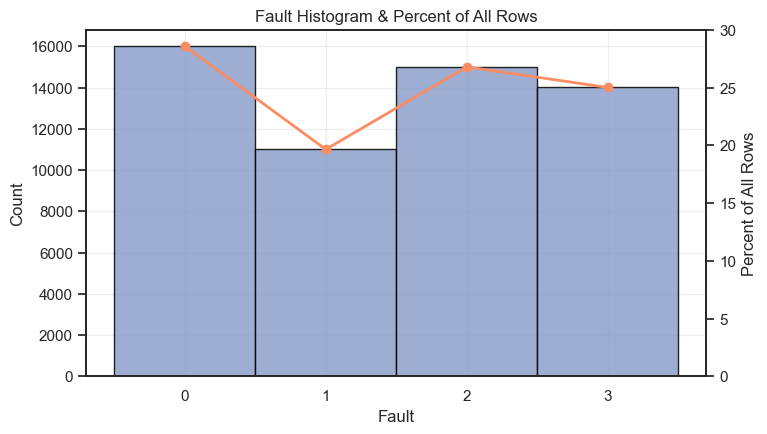

In [10]:
s = engines["Fault"].dropna()

# discrete values (e.g., 1..4)
vals = sorted(s.unique())
counts = s.value_counts().reindex(vals).fillna(0).astype(int)

# percent out of all rows (not cumulative)
pct = counts / counts.sum() * 100

# histogram-like bars (counts) + percentage labels/line on same x
bins = [v - 0.5 for v in vals] + [vals[-1] + 0.5]

sns.set_theme(style="white", palette="Set2")
bar_color = sns.color_palette("Set2")[2]
line_color = sns.color_palette("Set2")[1]

fig, ax1 = plt.subplots(figsize=(8, 4.5))

# histogram bars (counts)
ax1.hist(s, bins=bins, edgecolor="black", alpha=0.85, color=bar_color)
ax1.set_xticks(vals)
ax1.set_xlabel("Fault")
ax1.set_ylabel("Count")

# percentage line (percent of all rows)
ax2 = ax1.twinx()
ax2.plot(vals, pct.values, marker="o", linewidth=2, color=line_color)
ax2.set_ylabel("Percent of All Rows")
ax2.set_ylim(0, max(10, float(np.ceil(pct.max()/5)*5)))  # reasonable top

ax1.set_title("Fault Histogram & Percent of All Rows")
ax1.grid(True, alpha=0.3)

plt.show()


#### Plot Histogram and Boxplots (All Variables)

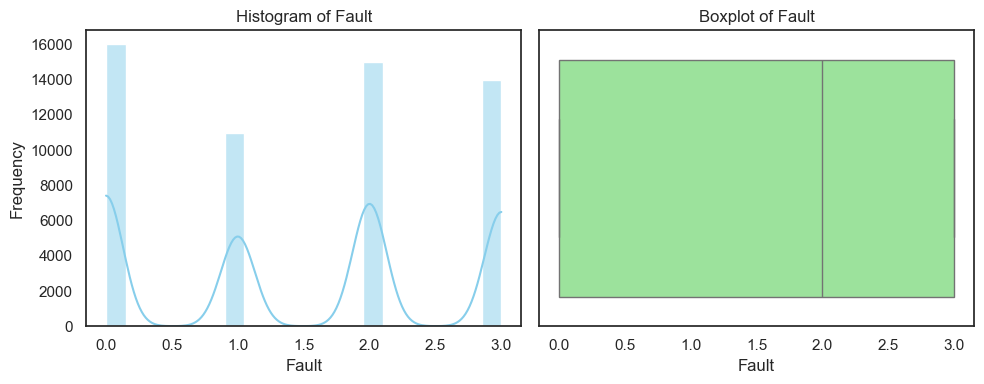

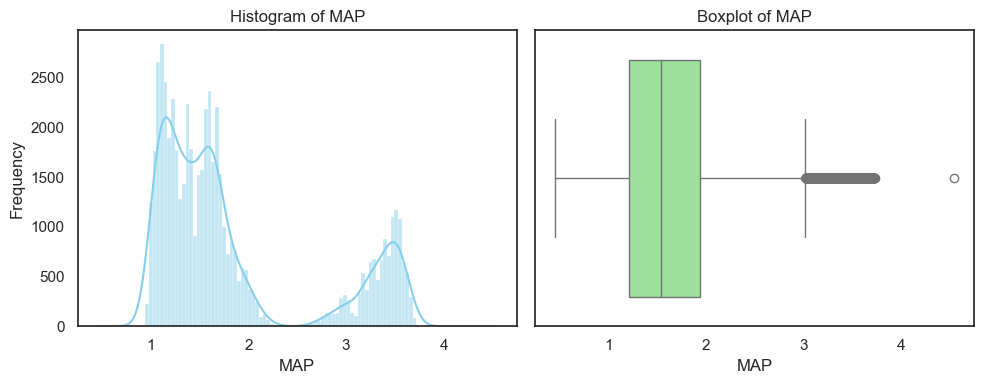

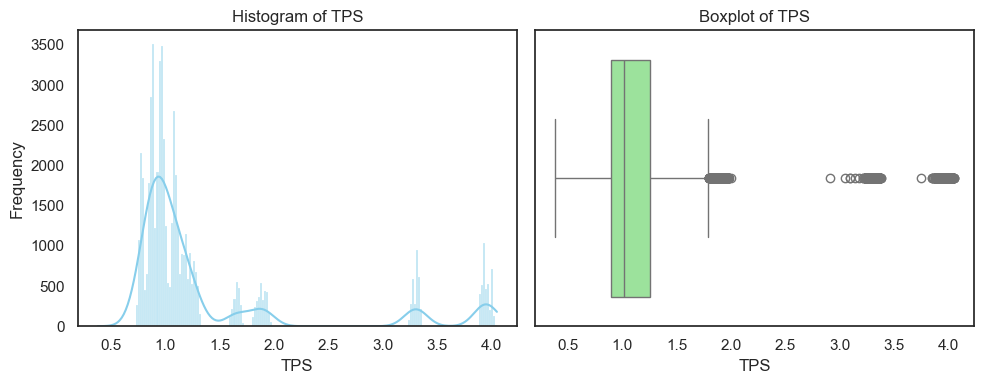

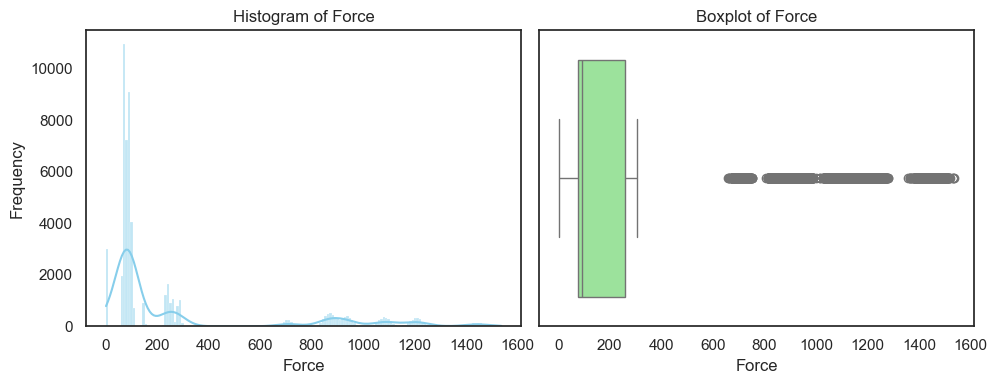

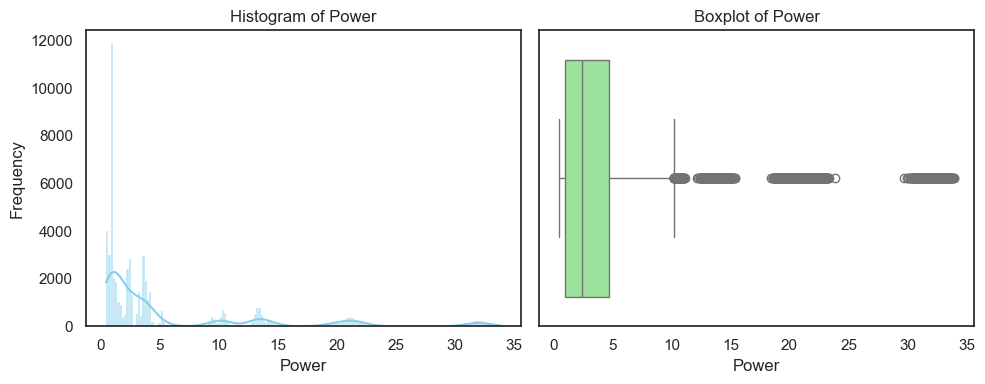

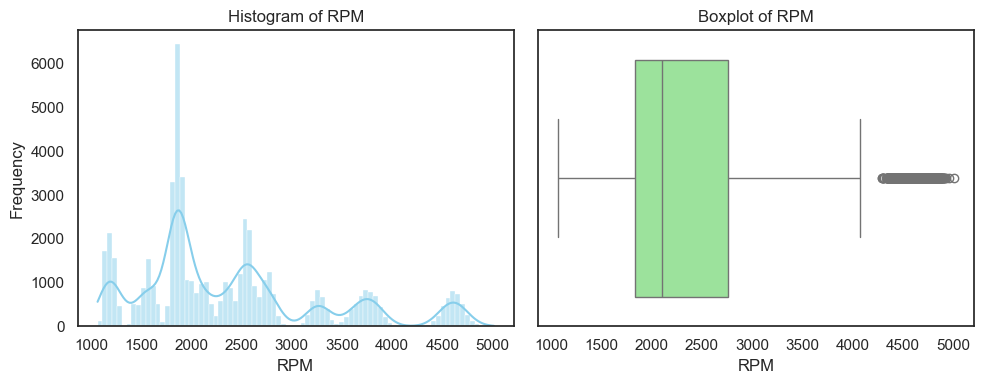

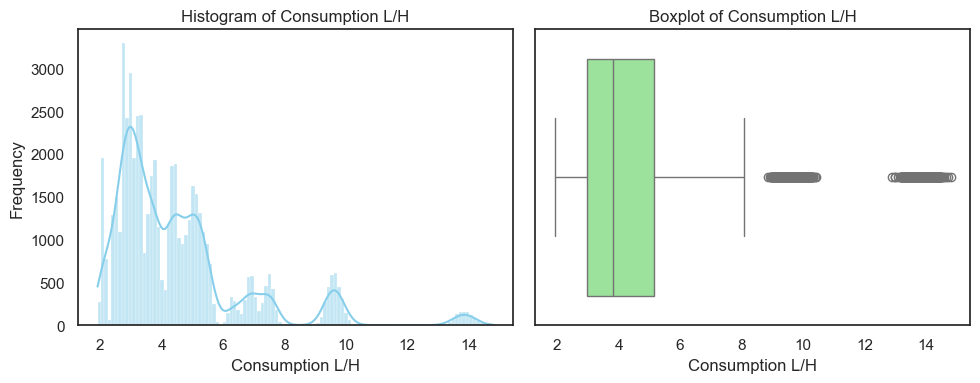

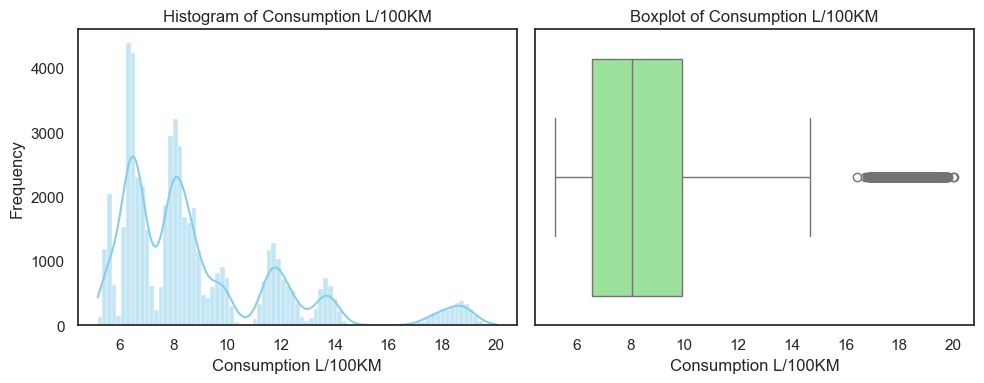

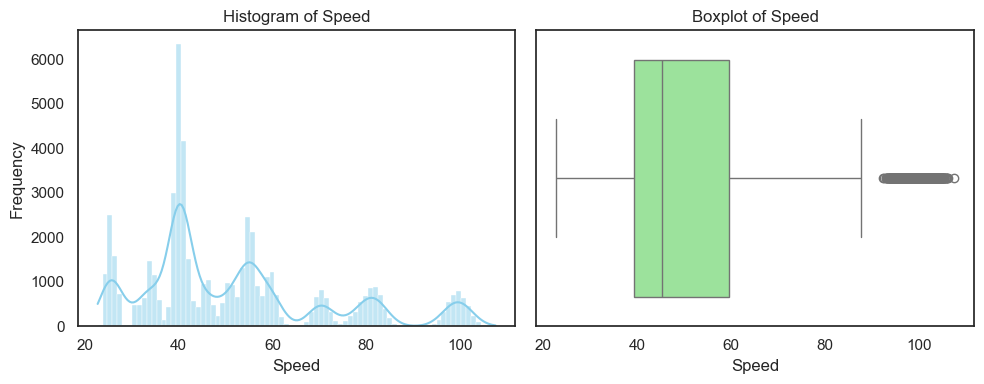

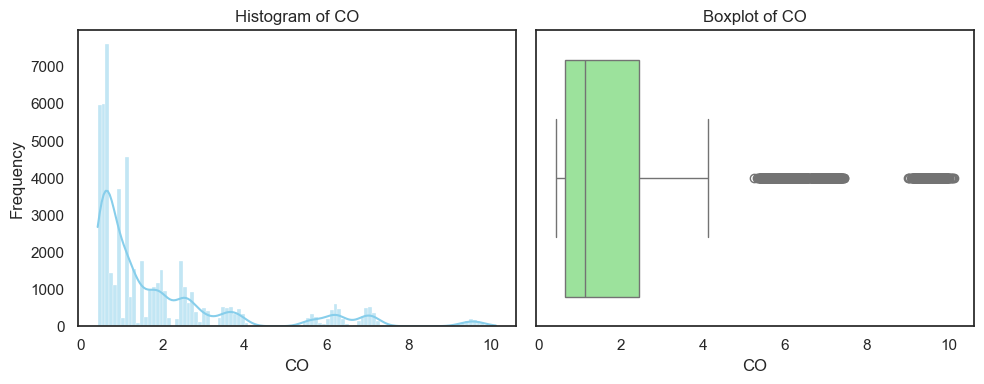

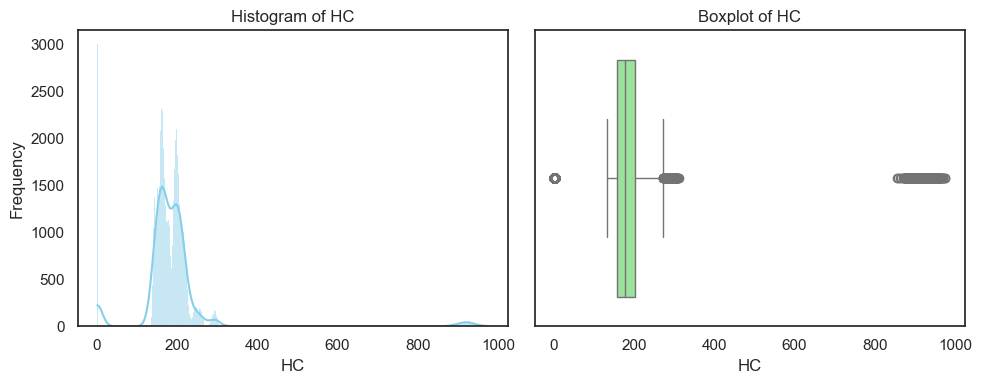

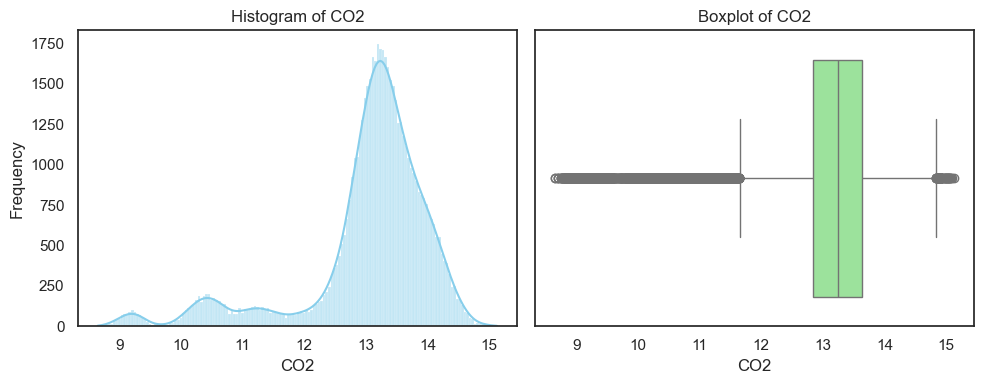

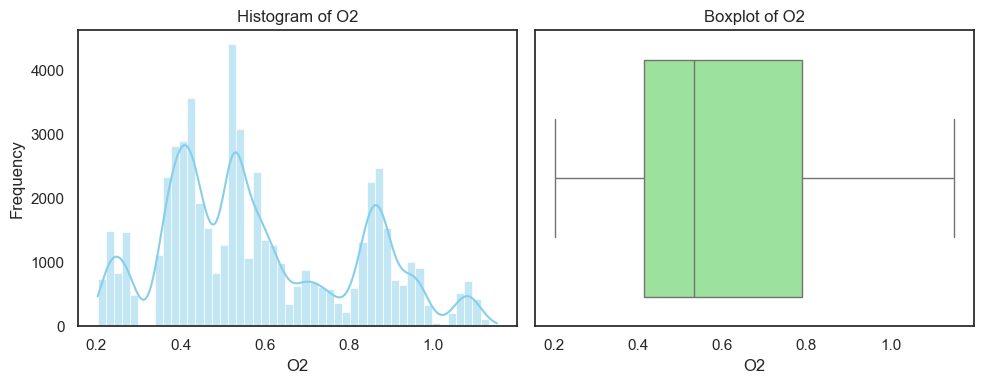

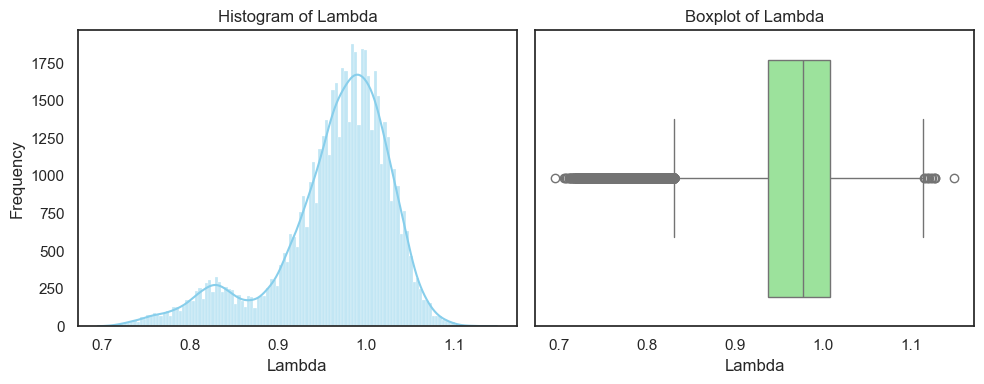

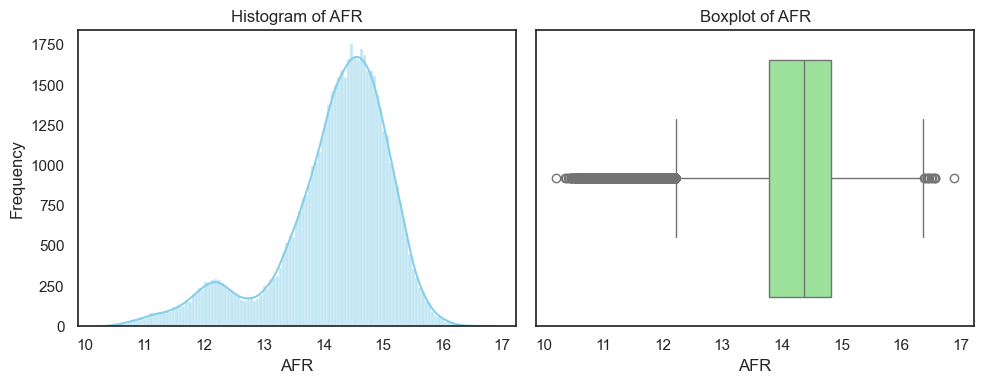

In [11]:
for col in engines.columns:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    
    # Histogram
    sns.histplot(engines[col].dropna(), kde=True, ax=axes[0], color='skyblue')
    axes[0].set_title(f'Histogram of {col}')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequency')
    
    # Boxplot
    sns.boxplot(x=engines[col], ax=axes[1], color='lightgreen')
    axes[1].set_title(f'Boxplot of {col}')
    axes[1].set_xlabel(col)
    
    plt.tight_layout()
    plt.show()

#### Heatmap of Variable Correlation

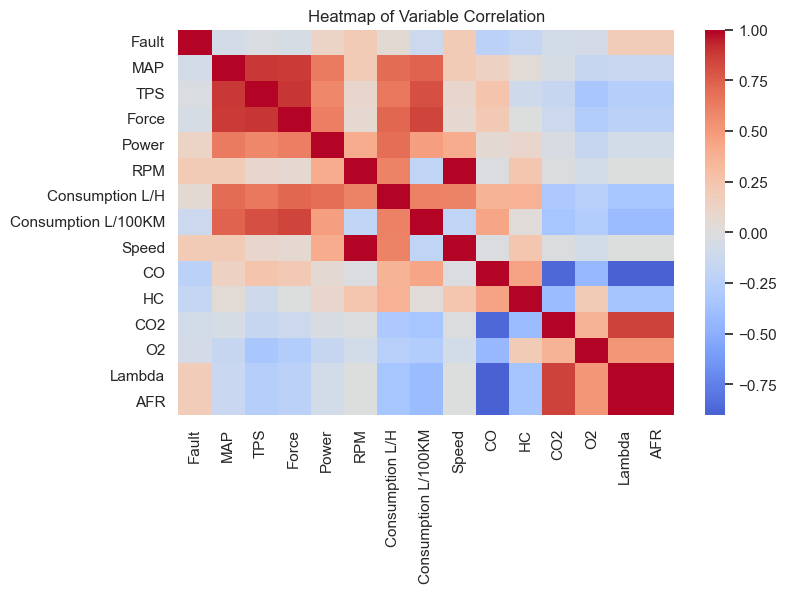

In [12]:
corr = engines.corr()
plt.figure(figsize=(8,5))
plt.title('Heatmap of Variable Correlation')
sns.heatmap(corr, cmap='coolwarm', center=0)
plt.show()

#### VIF Multicollinearity Check

In [13]:
# use VIF to check multicollinearity
# add constant for statsmodels
X_const = sm.add_constant(engines.iloc[:,1:])

vif_df_feature_selection = pd.DataFrame()
vif_df_feature_selection["variable"] = X_const.columns
vif_df_feature_selection["VIF"] = [variance_inflation_factor(X_const.values, i)
                 for i in range(X_const.shape[1])]
vif_df_feature_selection = vif_df_feature_selection[vif_df_feature_selection["variable"] != "const"]
print(vif_df_feature_selection.sort_values("VIF", ascending=False).head())

# VIF<3 -> no multicollinearity
# VIF 3-5 -> moderate
# VIF>5 -> high
def vif_categorizer(x):
    if x<=1:
        return 'none'
    if x>1 and x<=5:
        return 'moderate'
    if x>5:
        return 'high'
vif_df_feature_selection['multicollinearity'] = vif_df_feature_selection['VIF'].apply(lambda x: vif_categorizer(x))
vif_df_feature_selection.sort_values('VIF', ascending=False)

           variable           VIF
14              AFR  52064.931965
13           Lambda  52057.734318
5               RPM    168.748555
8             Speed    164.461881
6   Consumption L/H     36.357656


,variable,VIF,multicollinearity
14,AFR,52064.931965,high
13,Lambda,52057.734318,high
5,RPM,168.748555,high
8,Speed,164.461881,high
6,Consumption L/H,36.357656,high
7,Consumption L/100KM,25.763986,high
3,Force,11.245738,high
1,MAP,8.618050,high
2,TPS,8.571702,high
9,CO,8.489502,high


### Models

#### Variable Selection Subset

In [14]:
# generate splits
X = engines.iloc[:,1:]
y = engines.iloc[:,0]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=123)
# ridge regression
ridge = Ridge(alpha=1.0)
ridge.fit(X_train, y_train)
# lasso regression
lasso = Lasso(alpha=0.1)
lasso.fit(X_train, y_train)
df_feature_selection = pd.DataFrame()
df_feature_selection['Variable'] = X.columns
df_feature_selection["Ridge Coefficients"] = ridge.coef_
df_feature_selection['LASSO Coefficients'] = lasso.coef_

In [15]:
df_feature_selection.sort_values(by='Ridge Coefficients')
# deciding on ridge to avoid sparsity
#.1 * max(ridge coeff) = .142 -> used as threshold to keep variables

,Variable,Ridge Coefficients,LASSO Coefficients
10,CO2,-1.429820,-0.663214
11,O2,-1.018197,-0.000000
8,CO,-0.459436,-0.345425
6,Consumption L/100KM,-0.232141,-0.000000
0,MAP,-0.172101,-0.000000
7,Speed,-0.023660,-0.000000
9,HC,-0.002635,-0.002210
2,Force,-0.000158,-0.000231
4,RPM,0.000023,0.000240
3,Power,0.011600,0.016308


In [16]:
selected_features = df_feature_selection[(df_feature_selection['Ridge Coefficients']>.142) | (df_feature_selection['Ridge Coefficients']<-.142)].Variable

#### Defining engine-only, gas- or exhaust-only, and variable selection subsets

In [17]:
# engine characteristics only X
engine_characteristics = ['MAP', 'TPS', 'Force', 'Power', 'RPM', 'Consumption L/H', 'Consumption L/100KM', 'Speed']
engines_1 = engines[engine_characteristics]

# exhaust only X
exhaust_characteristics = ['CO', 'HC', 'CO2', 'O2', 'Lambda', 'AFR']
engines_2 = engines[exhaust_characteristics]

# variable selected X
engines_3 = engines[selected_features]

#### Models and Accuracies


KNN, feed-forward neural net, logistic regression, decision tree, random forest, Support Vector Classifier (SVC), Naive Bayes, QDA, LDA, and gradient boosting are applied with each variable subset and the accuracies are saved. Cross-validation is used and each fold is saved for later use in Wilcoxon Tests.

In [ ]:
def model_results(X, best_k):
    Ni = X.shape[1]      # number of input features (should be 14)
    No = len(np.unique(y))  # number of output classes (should be 4)
    Nh = int(0.5 * (Ni + No))  # Piramuthu rule → 9 neurons

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=123)

    #  BEST-K SEARCH FOR KNN (K = 1 → 25)
    best_k = None
    best_k_score = -1
    for k in range(1, 26):
        knn_model = Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=k))
        ])
        scores = cross_val_score(knn_model, X, y, cv=cv, scoring="accuracy")
        mean_score = scores.mean()

        if mean_score > best_k_score:
            best_k_score = mean_score
            best_k = k

    print(f"Best K found: {best_k} with accuracy={best_k_score:.4f}")

    #  FEED-FORWARD NN USING PURE SCIKIT-LEARN (MLPClassifier)
    ffnn_clf = MLPClassifier(
        hidden_layer_sizes=(Nh,),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=100,
        batch_size=64,
        early_stopping=True,
        n_iter_no_change=5,
        random_state=123
    )

    #  MODELS DICTIONARY
    models = {
        "Logistic Regression": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", LogisticRegression(max_iter=500))
        ]),
        "Decision Tree": DecisionTreeClassifier(random_state=123),
        "Random Forest": RandomForestClassifier(n_estimators=100, random_state=123),
        "SVC": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", SVC(kernel="rbf", probability=False, random_state=123))
        ]),
        "Best-K KNN": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", KNeighborsClassifier(n_neighbors=best_k))
        ]),
        "Naive Bayes": GaussianNB(),
        "Feed-Forward NN (Piramuthu Rule)": Pipeline([
            ("scaler", StandardScaler()),
            ("clf", ffnn_clf)
        ]),
        "QDA": QuadraticDiscriminantAnalysis(),
        "LDA": LinearDiscriminantAnalysis(),
        "Gradient Boosting": GradientBoostingClassifier(random_state=123)
    }

    #  SCORING METRICS
    scoring = {
        "accuracy": "accuracy",
        "precision": 'precision_macro',
        "recall": 'recall_macro',
        "f1": 'f1_macro'
    }

    #  CROSS-VALIDATION FOR ALL MODELS
    results = {}
    results_long = {}

    for name, model in models.items():
        scores = cross_validate(model, X, y, cv=cv, scoring=scoring, return_train_score=True)
        results[name] = {
            "train_accuracy": scores["train_accuracy"].mean(),
            "accuracy": scores["test_accuracy"].mean(),
            "precision": scores["test_precision"].mean(),
            "recall": scores["test_recall"].mean(),
            "f1": scores["test_f1"].mean()
        }
        results_long[name] = scores['test_f1']

        print(name, ' done')
    #  PRINT RESULTS
        for name, metrics in results.items():
            print(f"\n{name}")
            print(f"  Train Acc : {metrics['train_accuracy']:.4f}")
            print(f"  Val Acc   : {metrics['accuracy']:.4f}")
            print(f"  Precision : {metrics['precision']:.4f}")
            print(f"  Recall    : {metrics['recall']:.4f}")
            print(f"  F1        : {metrics['f1']:.4f}")
    return results, results_long

engines_1_results, engines_1_results_long = model_results(engines_1,4)
engines_2_results, engines_2_results_long = model_results(engines_2,3)
engines_3_results, engines_3_results_long = model_results(engines_3,23)

Best K found: 4 with accuracy=0.7393
Logistic Regression  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705
Decision Tree  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705

Decision Tree
  Train Acc : 1.0000
  Val Acc   : 0.7450
  Precision : 0.7527
  Recall    : 0.7525
  F1        : 0.7526
Random Forest  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705

Decision Tree
  Train Acc : 1.0000
  Val Acc   : 0.7450
  Precision : 0.7527
  Recall    : 0.7525
  F1        : 0.7526

Random Forest
  Train Acc : 1.0000
  Val Acc   : 0.7422
  Precision : 0.7498
  Recall    : 0.7500
  F1        : 0.7498
SVC  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705

Decision Tree
  Train 

c:\Users\nicol\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\nicol\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\nicol\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\nicol\anaconda3\Lib\site-packag

Feed-Forward NN (Piramuthu Rule)  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3971
  F1        : 0.3705

Decision Tree
  Train Acc : 1.0000
  Val Acc   : 0.7450
  Precision : 0.7527
  Recall    : 0.7525
  F1        : 0.7526

Random Forest
  Train Acc : 1.0000
  Val Acc   : 0.7422
  Precision : 0.7498
  Recall    : 0.7500
  F1        : 0.7498

SVC
  Train Acc : 0.6952
  Val Acc   : 0.6859
  Precision : 0.7039
  Recall    : 0.6924
  F1        : 0.6899

Best-K KNN
  Train Acc : 0.8370
  Val Acc   : 0.7393
  Precision : 0.7421
  Recall    : 0.7436
  F1        : 0.7348

Naive Bayes
  Train Acc : 0.3472
  Val Acc   : 0.3463
  Precision : 0.2956
  Recall    : 0.3286
  F1        : 0.2758

Feed-Forward NN (Piramuthu Rule)
  Train Acc : 0.6387
  Val Acc   : 0.6355
  Precision : 0.6389
  Recall    : 0.6401
  F1        : 0.6334
QDA  done

Logistic Regression
  Train Acc : 0.3895
  Val Acc   : 0.3871
  Precision : 0.4005
  Recall    : 0.3

In [ ]:
def write_engine_results(engine_number):
    # Dynamically select the correct dictionaries
    avg_results = globals()[f"engines_{engine_number}_results"]
    long_results = globals()[f"engines_{engine_number}_results_long"]

    # 1. Write average results
    with open(f"engines_{engine_number}_average_results.txt", "w") as f:
        for model_name, metrics in avg_results.items():
            f.write(f"Model: {model_name}\n")
            for metric, value in metrics.items():
                f.write(f"  {metric}: {value:.4f}\n")
            f.write("\n")

    # 2. Write fold-level results
    with open(f"engines_{engine_number}_fold_results.txt", "w") as f:
        for model_name, folds in long_results.items():
            f.write(f"{model_name} F1 scores per fold:\n")
            for i, score in enumerate(folds, start=1):
                f.write(f"  Fold {i}: {score:.4f}\n")
            f.write("\n")

    # 3. Wilcoxon + FDR significance
    pairs = list(itertools.combinations(long_results.keys(), 2))
    pvals = []

    for a, b in pairs:
        stat, p = wilcoxon(long_results[a], long_results[b])
        pvals.append(p)

    reject, pvals_corrected, _, _ = multipletests(pvals, method='fdr_bh')

    with open(f"engines_{engine_number}_wilcoxon_results.txt", "w") as f:
        for (a, b), p, pc, r in zip(pairs, pvals, pvals_corrected, reject):
            f.write(f"{a} vs {b}:\n")
            f.write(f"  raw p-value:       {p:.6f}\n")
            f.write(f"  FDR corrected p:   {pc:.6f}\n")
            f.write(f"  significant (FDR): {r}\n")
            f.write("\n")

    print(f"Finished writing results for engines_{engine_number}")


In [ ]:
write_engine_results(1)
write_engine_results(2)
write_engine_results(3)

KeyError: 'engines_1_results'

#### Wilcoxon Heatmap

Tests whether the differences observed are signficant without assuming normality. Each pair is evaluated within each variable subset.

In [ ]:
def wilcoxon_heatmap_all_models(eng1, eng2, eng3, alpha=0.10):
    models = list(eng1.keys())

    custom_abbrev = {
        "GradientBoosting": "GB",
        "GradientBoostingClassifier": "GB",
        "NeuralNet": "FFNN",
        "MLPClassifier": "FFNN",
        "NaiveBayes": "NB",
        "GaussianNB": "NB",
        "LogisticRegression": "LR",
        "DecisionTree": "DT",
        "DecisionTreeClassifier": "DT",
        "RandomForest": "RF",
        "RandomForestClassifier": "RF",
        "SVC": "SVC",
        "SupportVectorClassifier": "SVC",
        "KNN": "KNN",
        "KNeighborsClassifier": "KNN"
    }

    abbrev = {m: custom_abbrev.get(m, m.upper()) for m in models}

    comparisons = ["Engine vs Gas", "Engine vs VS", "Gas vs VS"]
    heatmap_data = pd.DataFrame(index=[abbrev[m] for m in models],
                                columns=comparisons)

    for model in models:
        data = {
            "Engine": eng1[model],
            "Gas": eng2[model],
            "VS": eng3[model]
        }

        pairs = [("Engine", "Gas"),
                 ("Engine", "VS"),
                 ("Gas", "VS")]

        raw_pvals = []
        for a, b in pairs:
            _, p = wilcoxon(data[a], data[b])
            raw_pvals.append(p)

        reject, corrected, _, _ = multipletests(raw_pvals, alpha=alpha, method='fdr_bh')
        heatmap_data.loc[abbrev[model], :] = corrected

    light_blue = "#a0cbf4"   # p >= 0.10
    orange     = "#ebb68b"   # p < 0.10

    cmap = ListedColormap([light_blue, orange])

    binary_mask = (heatmap_data.astype(float) < 0.10).astype(int)

    plt.figure(figsize=(10, 6))
    sns.heatmap(
        binary_mask,
        annot=heatmap_data.astype(float).round(4),
        fmt=".4f",
        cmap=cmap,
        linewidths=0.5,
        cbar=False
    )

    plt.title("Wilcoxon Significance Across All Models")
    plt.xlabel("Engine Comparison")
    plt.ylabel("Model")
    plt.tight_layout()
    plt.show()

    return heatmap_data


In [ ]:
wilcoxon_matrix = wilcoxon_heatmap_all_models(
    engines_1_results_long,
    engines_2_results_long,
    engines_3_results_long,
    alpha=0.10
)

print(wilcoxon_matrix)


In [ ]:
def plot_cv_distributions_separate(eng1, eng2, eng3, baseline=0.751):
    engines = {
        "Engine-Only": eng1,
        "Gas-Only": eng2,
        "Variable Selection": eng3
    }

    palette = sns.color_palette("Set2", 1)[0]

    fig, axes = plt.subplots(3, 1, figsize=(10,15), sharey=True)

    for ax, (engine_name, eng_data) in zip(axes, engines.items()):
        rows = []
        for model, scores in eng_data.items():
            for s in scores:
                rows.append({"Model": model, "F1": s})

        df = pd.DataFrame(rows)

        # --- filter out models with mean F1 < 0.7 ---
        model_means = df.groupby("Model")["F1"].mean()
        keep_models = model_means[model_means >= 0.7].index
        df = df[df["Model"].isin(keep_models)]

        sns.boxplot(
            data=df,
            x="Model",
            y="F1",
            color=palette,
            ax=ax
        )

        # orange baseline line
        ax.axhline(baseline, color="orange", linestyle="--", linewidth=2)

        ax.set_title(f"Cross-Validation F1 — {engine_name}")
        ax.set_xticklabels(ax.get_xticklabels(), rotation=45)


    fig.tight_layout()
    plt.show()


In [ ]:
plot_cv_distributions_separate(
    engines_1_results_long,
    engines_2_results_long,
    engines_3_results_long,
    baseline=0.751
)